In [2]:
import pandas as pd

df = pd.read_excel("online+retail/Online Retail.xlsx")

print(df.shape)

(541909, 8)


In [3]:
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
df["StockCode"] = df["StockCode"].astype(str)

این دو ستون ترکیبی از عدد و متن‌اند  همه‌شان را متن می‌کنیم تا بتوانیم با دستورهای متنی روی آن‌ها کار کنیم.

In [4]:
df["is_cancel"] = df["InvoiceNo"].str.startswith("C")

print(df["is_cancel"].value_counts())

is_cancel
False    532621
True       9288
Name: count, dtype: int64


فاکتورهایی که شماره‌شان با C شروع می‌شود لغو یا برگشتی هستند. این سلول یک ستون جدید می‌سازد که برای آن‌ها True و برای بقیه False است، و تعداد هرکدام را چاپ می‌کند.

In [5]:
print(df.dtypes)

InvoiceNo                 str
StockCode                 str
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
is_cancel                bool
dtype: object


In [6]:
df_clean = df.copy()
removed = []
print(len(df_clean))

541909


اول یک کپی از جدول می‌سازیم تا جدول اصلی (df) دست‌نخورده بماند. لیست removed هم برای نگه‌داشتن ردیف‌های حذف‌شده است.

In [7]:
mask = df_clean["InvoiceNo"].str.startswith("A")
print(mask.sum())
print(df_clean[mask][["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice"]])

removed.append(df_clean[mask].assign(reason="bad_debt"))
df_clean = df_clean[~mask]

3
       InvoiceNo StockCode      Description  Quantity  UnitPrice
299982   A563185         B  Adjust bad debt         1   11062.06
299983   A563186         B  Adjust bad debt         1  -11062.06
299984   A563187         B  Adjust bad debt         1  -11062.06


این‌ها فروش نیستند، ثبت «بدهی سوخت‌شده» هستند

In [8]:
non_product = ["POST", "DOT", "M", "m", "C2", "D", "S","BANK CHARGES", "AMAZONFEE", "CRUK", "B", "PADS"]

mask = df_clean["StockCode"].isin(non_product) | df_clean["StockCode"].str.startswith("gift_")
print(mask.sum())
print(df_clean[mask]["StockCode"].value_counts())

service_lines = df_clean[mask].copy()
df_clean = df_clean[~mask]

2947
StockCode
POST            1256
DOT              710
M                571
C2               144
D                 77
S                 63
BANK CHARGES      37
AMAZONFEE         34
CRUK              16
gift_0001_20      10
gift_0001_10       9
gift_0001_30       8
gift_0001_50       4
PADS               4
gift_0001_40       3
m                  1
Name: count, dtype: int64


POST (هزینه‌ی ارسال)، DOT، Manual، Bank Charges، Amazon Fee و کارت هدیه کالا نیستند. اگر در سبد خرید بمانند، قانون‌های انجمنی بی‌معنی می‌سازند. حذفشان نمی‌کنیم، در جدول جدا نگه می‌داریم چون ممکن است بعداً برای feature هزینه‌ی ارسال لازم شوند.

In [9]:
mask = df_clean["UnitPrice"] <= 0
print(mask.sum())

print(df_clean[mask]["CustomerID"].isna().mean())
print(df_clean[mask]["Description"].isna().mean())

removed.append(df_clean[mask].assign(reason="zero_price"))
df_clean = df_clean[~mask]

2497
0.986784140969163
0.579094913896676


فروش با قیمت صفر فروش واقعی نیست

حدود ۹۸٫۷٪ این ردیف‌ها CustomerID ندارند و حدود ۵۸٪ شان Description هم ندارند. این یعنی بیشترشان تعدیل انبار هستند، نه خریدی که فراموش شده مشتری‌اش ثبت شود.

In [10]:
mask = (df_clean["Quantity"] < 0) & (~df_clean["is_cancel"])
print(mask.sum())

0


Quantity منفی بدون C

In [11]:
mask = df_clean.duplicated()
print(mask.sum())

removed.append(df_clean[mask].assign(reason="duplicate"))
df_clean = df_clean[~mask]

5257


این‌ها ممکن است ثبت تکراری سیستم باشند یا یک مشتری که واقعاً دو بار همان کالا را اسکن کرده. داده نمی‌تواند تفکیک کند. فعلاً حذف می‌کنیم و بعداً اثرش را می‌سنجیم

In [12]:
excluded = pd.concat(removed)

print(len(df), len(df_clean), len(service_lines), len(excluded))
print(len(df) == len(df_clean) + len(service_lines) + len(excluded))
print(excluded["reason"].value_counts())

541909 531205 2947 7757
True
reason
duplicate     5257
zero_price    2497
bad_debt         3
Name: count, dtype: int64


In [13]:
sales = df_clean[(df_clean["is_cancel"] == False) & (df_clean["CustomerID"].notna())].copy()
sales["CustomerID"] = sales["CustomerID"].astype(int)
print(sales.shape)
print(sales["CustomerID"].nunique())

(391150, 9)
4334


جدول خرید مشتری‌های شناخته‌شده

In [14]:
print(sales["InvoiceDate"].min())
print(sales["InvoiceDate"].max())

2010-12-01 08:26:00
2011-12-09 12:50:00


بازه‌ی زمانی

In [15]:
print(sales.groupby(sales["InvoiceDate"].dt.to_period("M"))["CustomerID"].nunique())

InvoiceDate
2010-12     884
2011-01     739
2011-02     757
2011-03     973
2011-04     853
2011-05    1054
2011-06     990
2011-07     946
2011-08     933
2011-09    1259
2011-10    1361
2011-11    1660
2011-12     614
Freq: M, Name: CustomerID, dtype: int64


چند مشتری فعال در هر ماه

سپتامبر تا نوامبر هم بالاترین ماه‌هاست (فصل خرید کریسمس).

In [16]:
cutoff = pd.Timestamp("2011-09-11")

before = sales[sales["InvoiceDate"] < cutoff]
after = sales[sales["InvoiceDate"] >= cutoff]

customers_before = before["CustomerID"].unique()
customers_after = after["CustomerID"].unique()
print(len(customers_before), len(customers_after))

3368 2885


In [17]:
returned = set(customers_after)
churn_ids = [c for c in customers_before if c not in returned]

print(len(churn_ids))
print(len(churn_ids) / len(customers_before))

1449
0.43022565320665085


In [18]:
before = before.copy()
before["TotalPrice"] = before["Quantity"] * before["UnitPrice"]

ساخت ستون مبلغ هر ردیف

In [19]:
last_purchase = before.groupby("CustomerID")["InvoiceDate"].max()
recency = (cutoff - last_purchase).dt.days

آخرین تاریخ خرید هر مشتری را پیدا می‌کنیم و فاصله‌اش تا cutoff را به روز می‌گیریم

In [20]:
monetary = before.groupby("CustomerID")["TotalPrice"].sum()

مجموع مبلغ خریدهای هر مشتری.

In [21]:
label_table = pd.DataFrame({"CustomerID": customers_before})
label_table["churn"] = label_table["CustomerID"].isin(churn_ids).astype(int)

print(label_table.shape)
print(label_table["churn"].value_counts())

(3368, 2)
churn
0    1919
1    1449
Name: count, dtype: int64


ساخت جدول label

In [22]:
n_invoices = before.groupby("CustomerID")["InvoiceNo"].nunique()
label_table["n_invoices"] = label_table["CustomerID"].map(n_invoices)

print(label_table.head())

   CustomerID  churn  n_invoices
0       17850      1          34
1       13047      0           8
2       12583      0           9
3       13748      1           5
4       15100      1           3


می‌شماریم هر مشتری قبل از cutoff چند فاکتور داشته و کنار جدولمان می‌گذاریم.

In [23]:
label_table["for_classification"] = (label_table["n_invoices"] >= 2).astype(int)

print(label_table["for_classification"].value_counts())

for_classification
1    1998
0    1370
Name: count, dtype: int64


In [24]:
before = before.copy()
before["TotalPrice"] = before["Quantity"] * before["UnitPrice"]

print(before[["Quantity", "UnitPrice", "TotalPrice"]].head())

   Quantity  UnitPrice  TotalPrice
0         6       2.55       15.30
1         6       3.39       20.34
2         8       2.75       22.00
3         6       3.39       20.34
4         6       3.39       20.34


مبلغ هر ردیف برابر تعداد ضرب در قیمت واحد است. برای حساب کردن monetary لازم داریم

In [25]:
last_purchase = before.groupby("CustomerID")["InvoiceDate"].max()
recency = (cutoff - last_purchase).dt.days

print(recency.head())
print(recency.describe())

CustomerID
12346    235
12347     39
12348    158
12350    220
12352    172
Name: InvoiceDate, dtype: int64
count    3368.000000
mean       95.223575
std        80.050153
min         1.000000
25%        26.000000
50%        74.000000
75%       152.000000
max       283.000000
Name: InvoiceDate, dtype: float64


خط اول برای هر مشتری آخرین تاریخ خریدش را پیدا می‌کند. خط دوم فاصله‌ی آن تاریخ تا cutoff را به روز حساب می‌کند.

In [26]:
monetary = before.groupby("CustomerID")["TotalPrice"].sum()

print(monetary.head())
print(monetary.describe().round(1))

CustomerID
12346    77183.60
12347     2790.86
12348     1167.24
12350      294.40
12352      641.51
Name: TotalPrice, dtype: float64
count      3368.0
mean       1591.3
std        6091.1
min           2.9
25%         260.5
50%         555.0
75%        1360.8
max      177729.6
Name: TotalPrice, dtype: float64


Monetary یعنی مجموع خرجی که هر مشتری قبل از cutoff داشته

In [27]:
features = label_table[["CustomerID"]].copy()
features["recency"] = features["CustomerID"].map(recency)
features["frequency"] = features["CustomerID"].map(n_invoices)
features["monetary"] = features["CustomerID"].map(monetary)

print(features.shape)
print(features.isna().sum().sum())
print(features.head())

(3368, 4)
0
   CustomerID  recency  frequency  monetary
0       17850      282         34   5391.21
1       13047       37          8   2682.01
2       12583       16          9   3908.21
3       13748        5          5    948.25
4       15100      243          3    876.00


سه شاخصی که ساختیم (recency، n_invoices، monetary) هنوز جدا هستند. اینجا کنار هم می‌گذاریم تا یک جدول داشته باشیم که هر مشتری یک ردیف است

In [28]:
import numpy as np

features_log = features[["recency", "frequency", "monetary"]].copy()
features_log["frequency"] = np.log1p(features_log["frequency"])
features_log["monetary"] = np.log1p(features_log["monetary"])

print(features[["recency", "frequency", "monetary"]].skew().round(2))
print(features_log.skew().round(2))

recency       0.76
frequency     9.17
monetary     16.28
dtype: float64
recency      0.76
frequency    1.38
monetary     0.41
dtype: float64


لگاریتم اعداد بزرگ را فشرده می‌کند. از log1p استفاده می‌کنیم، یعنی لگاریتم (عدد + ۱)، تا اگر عددی صفر بود مشکل نداشته باشیم. روی recency لازم نیست، چون کجی‌اش کم است.

In [30]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(features_log)

X_df = pd.DataFrame(X, columns=["recency", "frequency", "monetary"])
print(X_df.describe().round(2))

       recency  frequency  monetary
count  3368.00    3368.00   3368.00
mean     -0.00       0.00      0.00
std       1.00       1.00      1.00
min      -1.18      -0.87     -4.14
25%      -0.86      -0.87     -0.69
50%      -0.27      -0.22     -0.07
75%       0.71       0.59      0.67
max       2.35       5.82      4.66


In [31]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X)
    print(k, round(km.inertia_, 1), round(silhouette_score(X, labels), 3))

2 5228.0 0.411
3 3520.5 0.373
4 2724.5 0.345
5 2346.9 0.325
6 2029.0 0.317
7 1824.5 0.302
8 1672.8 0.28


انتخاب تعداد خوشه (k)

## انتخاب تعداد خوشه‌ها (k) برای KMeans

الگوریتم KMeans باید از قبل بداند چند خوشه بسازد، پس k را با دو معیار برای مقدارهای ۲ تا ۸ بررسی کردیم:

- **Inertia (روش elbow):** مجموع فاصله‌ی هر مشتری تا مرکز خوشه‌اش. با زیاد شدن k همیشه کم می‌شود. دنبال نقطه‌ای هستیم که بعد از آن کاهش کند شود (شکل آرنج).
- **Silhouette:** میزان جدا بودن خوشه‌ها از هم. مقدارش بین ۱- و ۱ است و هرچه بزرگ‌تر باشد بهتر است.

### نتایج

| k | Inertia | Silhouette |
|---|---|---|
| 2 | 5228.0 | 0.411 |
| 3 | 3520.5 | 0.373 |
| 4 | 2724.5 | 0.345 |
| 5 | 2346.9 | 0.325 |
| 6 | 2029.0 | 0.317 |
| 7 | 1824.5 | 0.302 |
| 8 | 1672.8 | 0.280 |

### تفسیر

- **Elbow:** تا k=4 کاهش inertia زیاد است (۱۷۰۷، سپس ۷۹۶). بعد از آن کاهش‌ها کوچک و تقریباً هم‌اندازه می‌شوند (۳۷۸، ۳۱۸، ...). آرنج حدود **k=4** است.
- **Silhouette:** بالاترین مقدار مربوط به k=2 است (۰.۴۱۱)، ولی k=3 و k=4 هم دور از آن نیستند. مقدار حدود ۰.۳۵ یعنی ساختار خوشه‌ای **متوسط** است: خوشه‌ها تا حدی جدا هستند ولی مرزشان تیز نیست. برای داده‌ی رفتار مشتری این طبیعی است، چون مشتری‌ها بیشتر یک پیوستار هستند تا گروه‌های کاملاً جدا.

### تصمیم: k = 4

دلایل:

1. آرنج نمودار inertia روی همین مقدار است.
2. افت silhouette از k=2 به k=4 آن‌قدر نیست که مانع انتخاب شود.
3. k=2 فقط مشتری‌ها را به دو گروه کلی تقسیم می‌کند و برای تحلیل رفتار کم‌فایده است. با چهار گروه می‌توان رفتارهای متفاوتی را از هم تفکیک کرد.

> **توجه:** این انتخاب یک قضاوت تحلیلی است، نه نتیجه‌ی قطعی ریاضی. در مرحله‌ی بعد با توصیف رفتار هر خوشه بررسی می‌کنیم که این تقسیم‌بندی معنادار هست یا نه.

In [32]:
km = KMeans(n_clusters=4, random_state=42, n_init=10)
features["cluster"] = km.fit_predict(X)

print(features["cluster"].value_counts().sort_index())

cluster
0    1118
1     886
2     479
3     885
Name: count, dtype: int64


In [33]:
profile = features.groupby("cluster")[["recency", "frequency", "monetary"]].mean().round(1)
profile["size"] = features["cluster"].value_counts().sort_index()
print(profile)

         recency  frequency  monetary  size
cluster                                    
0           56.7        3.3    1303.8  1118
1          208.3        1.2     351.4   886
2           24.4       12.2    6939.5   479
3           69.0        1.4     301.1   885


معنی هر خوشه
خوشه ۲ (۴۷۹ نفر): مشتری‌های برتر. تازه خریده‌اند (حدود ۲۴ روز پیش)، به‌طور میانگین ۱۲ فاکتور دارند و خرجشان خیلی بیشتر از بقیه است.


خوشه ۰ (۱۱۱۸ نفر): مشتری‌های منظم متوسط. نسبتاً تازه، سه فاکتور، خرج متوسط.


خوشه ۳ (۸۸۵ نفر): مشتری‌های جدید یا کم‌خرید. تقریباً یک فاکتور (۱٫۴)، خرج کم، و آخرین خریدشان حدود ۶۹ روز پیش بوده.


خوشه ۱ (۸۸۶ نفر): مشتری‌های دور‌شده. یک فاکتور (۱٫۲)، خرج کم، و آخرین خریدشان حدود ۲۰۸ روز پیش بوده. به‌نظر می‌رسد خیلی وقت است نیامده‌اند.

In [34]:
features = features.merge(label_table[["CustomerID", "churn"]], on="CustomerID")
print(features.shape)

(3368, 6)


ستون churn را از label_table با کمک CustomerID به features می‌چسبانیم. از merge استفاده می‌کنیم تا ترتیب ردیف‌ها مهم نباشد.

In [35]:
churn_by_cluster = features.groupby("cluster")["churn"].agg(["mean", "sum", "count"])
print(churn_by_cluster.round(3))
print(features["churn"].mean().round(3))

          mean  sum  count
cluster                   
0        0.318  355   1118
1        0.661  586    886
2        0.067   32    479
3        0.538  476    885
0.43


خوشه ۲ (مشتری‌های برتر): فقط ۶٫۷٪ ریزش. تقریباً همه می‌مانند


خوشه ۱ (دورشده‌ها): ۶۶٪ ریزش، بالاترین. با توصیف قبلی‌مان (آخرین خرید حدود ۲۰۸ روز پیش) جور است


خوشه ۳ (تازه‌واردها / کم‌خرید): ۵۳٫۸٪ ریزش


خوشه ۰ (منظم متوسط): ۳۱٫۸٪ ریزش

یعنی خوشه‌ها ریزش را خوب تفکیک می‌کنند: از ۶٫۷٪ تا ۶۶٪. این یعنی رفتار مشتری قبل از cutoff واقعاً به اتفاقی که بعد از cutoff افتاده مربوط است، و خوشه‌ها به‌عنوان feature برای classification ارزش دارند.

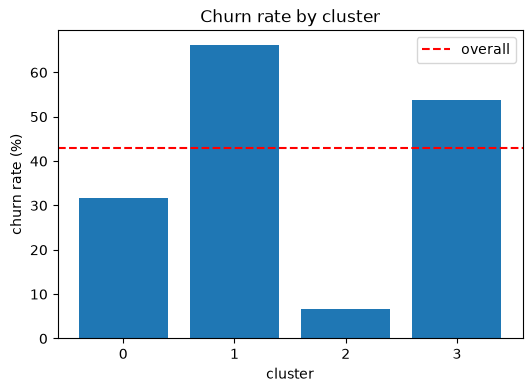

In [36]:
import matplotlib.pyplot as plt

rate = features.groupby("cluster")["churn"].mean()

plt.figure(figsize=(6, 4))
plt.bar(rate.index.astype(str), rate.values * 100)
plt.axhline(features["churn"].mean() * 100, color="red", linestyle="--", label="overall")
plt.xlabel("cluster")
plt.ylabel("churn rate (%)")
plt.title("Churn rate by cluster")
plt.legend()
plt.show()

این نمودار نرخ ریزش مشتریان را در چهار خوشه (Cluster 0 تا 3) با یکدیگر مقایسه می‌کند. خط قرمزِ چین‌دار هم نرخ ریزش کل مشتریان را نشان می‌دهد که حدود ۴۳٪ است

۱. تحلیل هر خوشه
Cluster 0
نرخ ریزش: حدود ۳۲٪

پایین‌تر از میانگین کل است. مشتریان این خوشه نسبت به میانگین، ریزش کمتری دارند.



Cluster 1
نرخ ریزش: حدود ۶۶٪

بالاترین نرخ ریزش را دارد. تقریباً دو سوم مشتریان این خوشه ریزش کرده‌اند. این گروه مهم‌ترین گزینه برای بررسی عوامل ریزش است.



Cluster 2
نرخ ریزش: حدود ۷٪

کمترین نرخ ریزش را دارد. به نظر می‌رسد مشتریان این گروه رفتار باثبات‌تری داشته‌اند.



Cluster 3
نرخ ریزش: حدود ۵۴٪

نرخ ریزش آن از میانگین کل بیشتر است؛ بنابراین این خوشه نیز گروهی قابل‌توجه از مشتریان در معرض ریزش را شامل می‌شود.